# Iris Flower Classification

### QSkill Artificial Intelligence & Machine Learning Internship

## Objective

Classify iris flowers into three species — Setosa, Versicolor, and Virginica —
based on measurements of their petals and sepals.

## Dataset

The classic Iris dataset available through scikit-learn is used.

## Steps

1. Load the dataset and explore it visually.
2. Split the data into training and testing sets.
3. Preprocess the data if needed.
4. Train a simple classification model.
5. Evaluate the model using accuracy, precision, and confusion matrix.

In [ ]:
# Import required libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
# Load the Iris dataset

iris = load_iris()

print("Iris dataset loaded successfully!")

Iris dataset loaded successfully!


In [ ]:
# Convert the dataset into a Pandas DataFrame

df = pd.DataFrame(
    iris.data,
    columns=iris.feature_names
)

# Add target values
df["target"] = iris.target

# Add species names
df["species"] = df["target"].map(
    dict(enumerate(iris.target_names))
)

df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target,species
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa


In [ ]:
# Display dataset shape

print("Number of rows and columns:", df.shape)

# Display column names

print("\nColumn names:")
print(df.columns.tolist())

Number of rows and columns: (150, 6)

Column names:
['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)', 'target', 'species']


In [ ]:
# Display basic information about the dataset

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   target             150 non-null    int64  
 5   species            150 non-null    object 
dtypes: float64(4), int64(1), object(1)
memory usage: 7.2+ KB


In [ ]:
# Statistical summary

df.describe()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333,1.000000
std,0.828066,0.435866,1.765298,0.762238,0.819232
min,4.300000,2.000000,1.000000,0.100000,0.000000
25%,5.100000,2.800000,1.600000,0.300000,0.000000
50%,5.800000,3.000000,4.350000,1.300000,1.000000
75%,6.400000,3.300000,5.100000,1.800000,2.000000
max,7.900000,4.400000,6.900000,2.500000,2.000000


In [ ]:
# Check for missing values

print("Missing values in each column:")
print(df.isnull().sum())

Missing values in each column:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
target               0
species              0
dtype: int64


In [ ]:
# Count the number of samples in each species

print(df["species"].value_counts())

species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


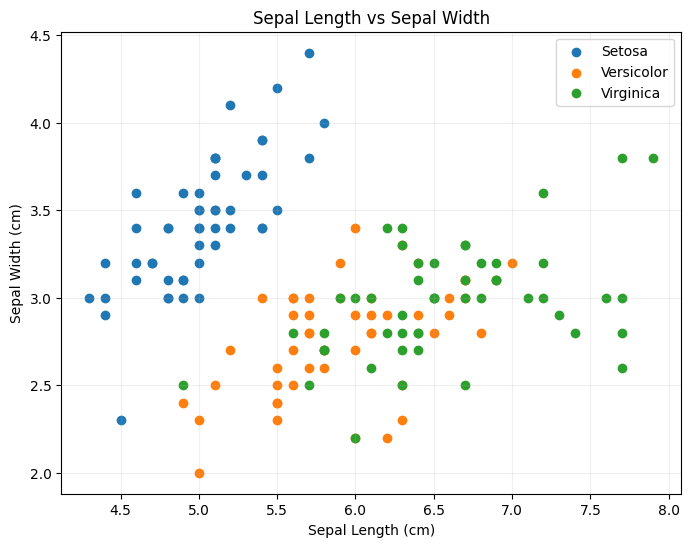

In [ ]:
# Scatter plot: Sepal Length vs Sepal Width

plt.figure(figsize=(8, 6))

for species in iris.target_names:
    subset = df[df["species"] == species]

    plt.scatter(
        subset["sepal length (cm)"],
        subset["sepal width (cm)"],
        label=species.capitalize()
    )

plt.xlabel("Sepal Length (cm)")
plt.ylabel("Sepal Width (cm)")
plt.title("Sepal Length vs Sepal Width")
plt.legend()
plt.grid(alpha=0.2)

plt.show()

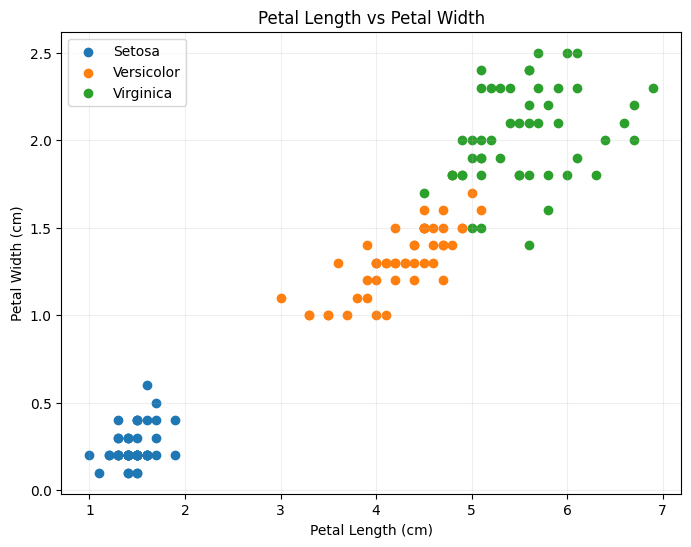

In [ ]:
# Scatter plot: Petal Length vs Petal Width

plt.figure(figsize=(8, 6))

for species in iris.target_names:
    subset = df[df["species"] == species]

    plt.scatter(
        subset["petal length (cm)"],
        subset["petal width (cm)"],
        label=species.capitalize()
    )

plt.xlabel("Petal Length (cm)")
plt.ylabel("Petal Width (cm)")
plt.title("Petal Length vs Petal Width")
plt.legend()
plt.grid(alpha=0.2)

plt.show()

In [ ]:
# Separate input features (X) and target (y)

X = df[iris.feature_names]
y = df["target"]

print("Features:")
display(X.head())

print("\nTarget:")
display(y.head())

Features:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2



Target:


,target
0,0
1,0
2,0
3,0
4,0


In [ ]:
from sklearn.model_selection import train_test_split

# Split the dataset into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 120
Testing samples: 30


In [ ]:
from sklearn.preprocessing import StandardScaler

# Create the scaler
scaler = StandardScaler()

# Fit the scaler only on training data
X_train_scaled = scaler.fit_transform(X_train)

# Transform the test data using the same scaler
X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed successfully!")

Feature scaling completed successfully!


In [ ]:
from sklearn.linear_model import LogisticRegression

# Create the Logistic Regression model
model = LogisticRegression(max_iter=200)

# Train the model
model.fit(X_train_scaled, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [ ]:
# Make predictions on the test data

y_pred = model.predict(X_test_scaled)

print("Predictions:")
print(y_pred)

Predictions:
[0 2 1 1 0 1 0 0 2 1 2 2 2 1 0 0 0 1 1 2 0 2 1 1 2 2 1 0 2 0]


In [ ]:
# Compare actual and predicted values

comparison = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_pred
})

comparison.head(10)

,Actual,Predicted
0,0,0
1,2,2
2,1,1
3,1,1
4,0,0
5,1,1
6,0,0
7,0,0
8,2,2
9,1,1


In [ ]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print(f"Accuracy: {accuracy:.4f}")

Accuracy: 0.9333


In [ ]:
from sklearn.metrics import precision_score

precision = precision_score(
    y_test,
    y_pred,
    average="weighted"
)

print(f"Precision: {precision:.4f}")

Precision: 0.9333


In [ ]:
from sklearn.metrics import classification_report

print(classification_report(
    y_test,
    y_pred,
    target_names=iris.target_names
))

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



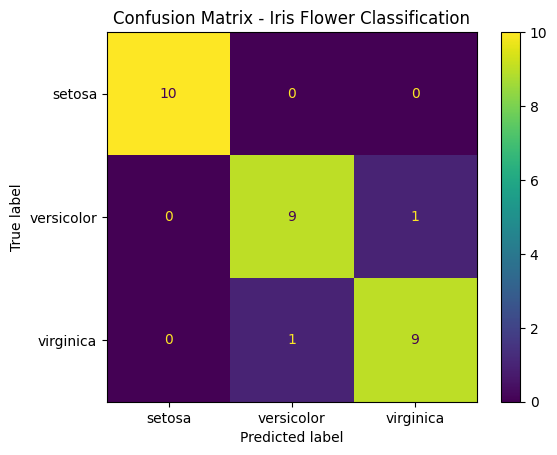

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=iris.target_names
)

disp.plot()
plt.title("Confusion Matrix - Iris Flower Classification")
plt.show()

## Additional Model: Decision Tree

As an additional classification experiment, a Decision Tree classifier was
trained using the same training and testing data.

The Decision Tree does not require feature scaling because it makes decisions
using feature-based splitting rules.


In [ ]:
from sklearn.tree import DecisionTreeClassifier

# Create the Decision Tree model
decision_tree = DecisionTreeClassifier(random_state=42)

# Train the model
decision_tree.fit(X_train, y_train)

print("Decision Tree model trained successfully!")

Decision Tree model trained successfully!


In [ ]:
# Make predictions using the Decision Tree

y_pred_dt = decision_tree.predict(X_test)

print("Decision Tree predictions:")
print(y_pred_dt)

Decision Tree predictions:
[0 2 1 1 0 1 0 0 2 1 2 2 2 1 0 0 0 1 1 2 0 2 1 1 2 2 1 0 2 0]


In [ ]:
from sklearn.metrics import accuracy_score

accuracy_dt = accuracy_score(y_test, y_pred_dt)

print(f"Decision Tree Accuracy: {accuracy_dt:.4f}")
print(f"Decision Tree Accuracy: {accuracy_dt * 100:.2f}%")

Decision Tree Accuracy: 0.9333
Decision Tree Accuracy: 93.33%


In [ ]:
from sklearn.metrics import precision_score

precision_dt = precision_score(
    y_test,
    y_pred_dt,
    average="weighted"
)

print(f"Decision Tree Precision: {precision_dt:.4f}")
print(f"Decision Tree Precision: {precision_dt * 100:.2f}%")

Decision Tree Precision: 0.9333
Decision Tree Precision: 93.33%


In [ ]:
from sklearn.metrics import classification_report

print("Decision Tree Classification Report:\n")

print(
    classification_report(
        y_test,
        y_pred_dt,
        target_names=iris.target_names
    )
)

Decision Tree Classification Report:

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



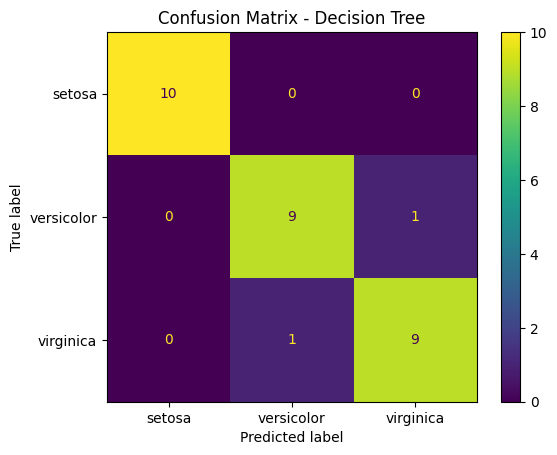

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm_dt = confusion_matrix(y_test, y_pred_dt)

disp_dt = ConfusionMatrixDisplay(
    confusion_matrix=cm_dt,
    display_labels=iris.target_names
)

disp_dt.plot()
plt.title("Confusion Matrix - Decision Tree")
plt.show()

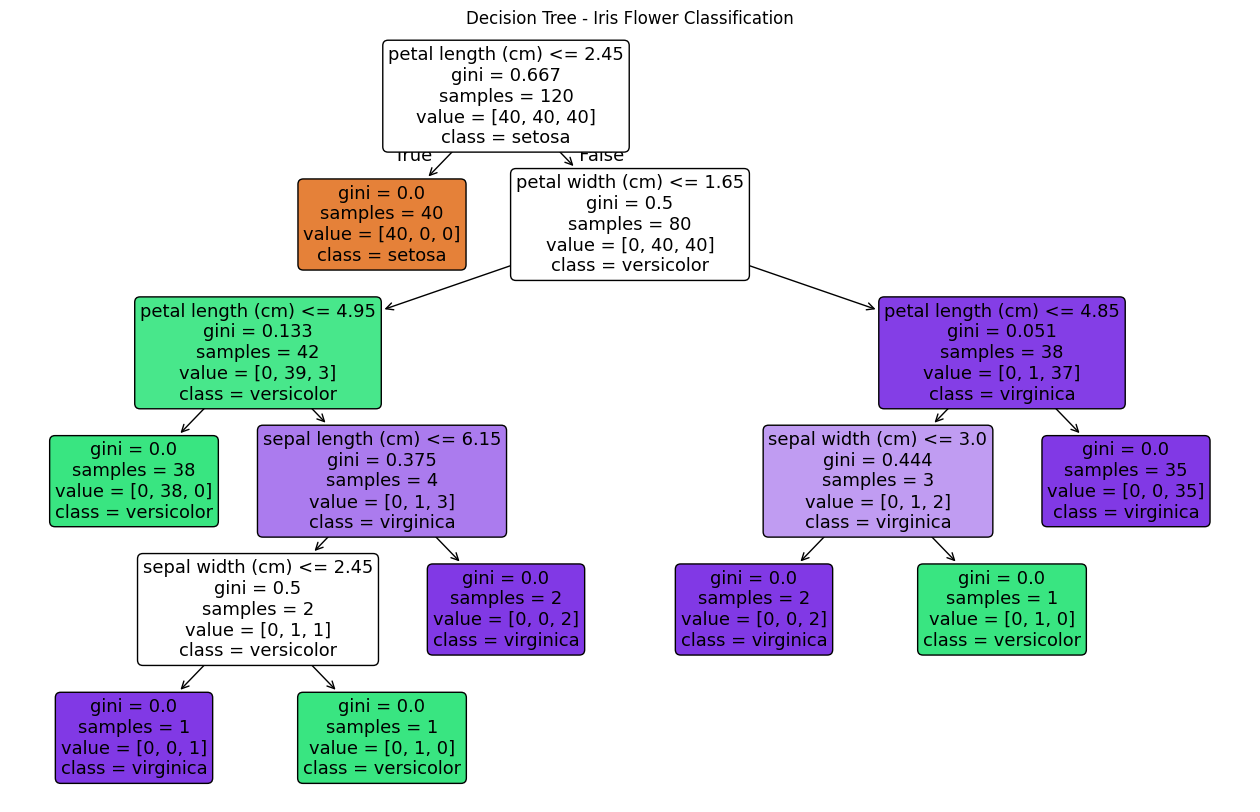

In [ ]:
from sklearn.tree import plot_tree

plt.figure(figsize=(16, 10))

plot_tree(
    decision_tree,
    feature_names=iris.feature_names,
    class_names=iris.target_names,
    filled=True,
    rounded=True
)

plt.title("Decision Tree - Iris Flower Classification")
plt.show()

## Additional Model: K-Nearest Neighbours (KNN)

K-Nearest Neighbours (KNN) was used as another classification algorithm for
the Iris Flower Classification task.

KNN classifies a new data point by looking at the nearest data points in the
training dataset and assigning the most common class among them.

In this project, KNN was configured with 5 neighbours (`n_neighbors=5`).

Feature scaling was used before applying KNN because KNN is a distance-based
algorithm. The scaled training data was used to train the model, and the
scaled test data was used for prediction.

The KNN model was evaluated using accuracy, weighted precision,
classification report, and confusion matrix.


In [ ]:
from sklearn.neighbors import KNeighborsClassifier

# Create the KNN model
knn = KNeighborsClassifier(n_neighbors=5)

# Train the model using scaled training data
knn.fit(X_train_scaled, y_train)

print("KNN model trained successfully!")

KNN model trained successfully!


In [ ]:
# Make predictions using KNN

y_pred_knn = knn.predict(X_test_scaled)

print("KNN predictions:")
print(y_pred_knn)

KNN predictions:
[0 2 1 1 0 1 0 0 2 1 2 2 2 1 0 0 0 1 1 1 0 2 1 1 2 1 1 0 2 0]


In [ ]:
from sklearn.metrics import accuracy_score

accuracy_knn = accuracy_score(y_test, y_pred_knn)

print(f"KNN Accuracy: {accuracy_knn:.4f}")
print(f"KNN Accuracy: {accuracy_knn * 100:.2f}%")

KNN Accuracy: 0.9333
KNN Accuracy: 93.33%


In [ ]:
from sklearn.metrics import precision_score

precision_knn = precision_score(
    y_test,
    y_pred_knn,
    average="weighted"
)

print(f"KNN Precision: {precision_knn:.4f}")
print(f"KNN Precision: {precision_knn * 100:.2f}%")

KNN Precision: 0.9444
KNN Precision: 94.44%


In [ ]:
from sklearn.metrics import classification_report

print("KNN Classification Report:\n")

print(
    classification_report(
        y_test,
        y_pred_knn,
        target_names=iris.target_names
    )
)

KNN Classification Report:

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.83      1.00      0.91        10
   virginica       1.00      0.80      0.89        10

    accuracy                           0.93        30
   macro avg       0.94      0.93      0.93        30
weighted avg       0.94      0.93      0.93        30



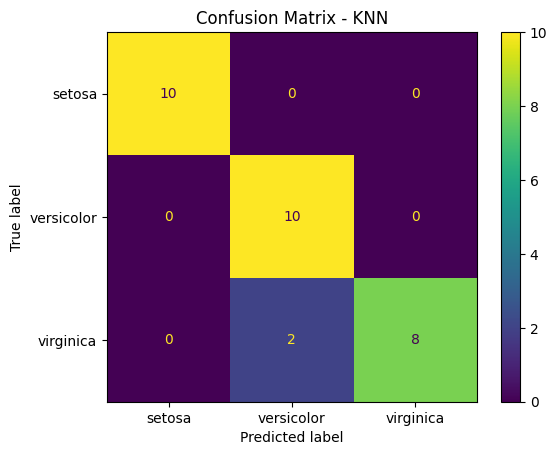

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm_knn = confusion_matrix(y_test, y_pred_knn)

disp_knn = ConfusionMatrixDisplay(
    confusion_matrix=cm_knn,
    display_labels=iris.target_names
)

disp_knn.plot()
plt.title("Confusion Matrix - KNN")
plt.show()

## Model Comparison

Three classification algorithms were tested using the Iris dataset:

1. Logistic Regression
2. Decision Tree
3. K-Nearest Neighbours (KNN)

All three models were evaluated using the same test dataset.

| Model | Accuracy | Weighted Precision |
|---|---:|---:|
| Logistic Regression | 93.33% | 93.33% |
| Decision Tree | 93.33% | 93.33% |
| KNN | 93.33% | 94.44% |

All three models achieved an accuracy of 93.33% on the test set.
The KNN model produced a weighted precision of 94.44%.


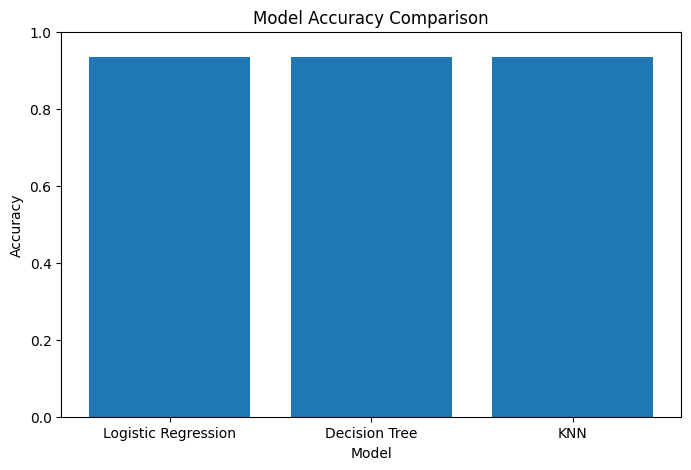

In [ ]:
# Model performance comparison

models = ["Logistic Regression", "Decision Tree", "KNN"]
accuracies = [accuracy, accuracy_dt, accuracy_knn]

plt.figure(figsize=(8, 5))
plt.bar(models, accuracies)

plt.ylim(0, 1)
plt.ylabel("Accuracy")
plt.xlabel("Model")
plt.title("Model Accuracy Comparison")

plt.show()

# Conclusion

The Iris Flower Classification project was successfully completed using
three machine learning classification algorithms: Logistic Regression,
Decision Tree, and K-Nearest Neighbours (KNN).

The Iris dataset was explored using statistical analysis and scatter plots.
The dataset was also checked for missing values and was found to be clean.

The data was divided into training and testing sets, and StandardScaler was
used for the models that benefit from feature scaling.

All three models achieved an accuracy of 93.33% on the test dataset.
The KNN model achieved a weighted precision of 94.44%, while Logistic
Regression and Decision Tree achieved a weighted precision of 93.33%.

The confusion matrices were used to examine the correct and incorrect
predictions for each flower species.

Overall, the project demonstrates the complete machine learning workflow
from data exploration and preprocessing to model training, prediction,
evaluation, and comparison.